# Part C: Part-to-whole legality, and the pie-ranking experiment (9 marks)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from vizlib import PALETTE, style_defaults, save_fig   # Week 3 toolkit
import tslib                                           # Week 4 toolkit

%matplotlib inline
style_defaults()

DATA = Path("data")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def save(fig, name, note=None):
    """fig.savefig first (300 dpi, tight), THEN the figure is shown."""
    save_fig(fig, FIG / name, note)

def check(label, ok, detail=""):
    print(f"[{'PASS' if ok else 'FAIL'}] {label} {detail}")
import time, csv

## 1. The three conditions, tested in code (3 marks)
Exclusive parts, a meaningful whole, and the share being the actual question. `exclusivity_check` does test 1; tests 2 and 3 are arguments.

### Table 1: the four `touch_*` columns of case08

In [2]:
c8 = pd.read_csv(DATA / "case08_channel_attrib.csv")
r = tslib.exclusivity_check(c8, [c for c in c8.columns if c.startswith("touch_")])
r

{'n': 4000,
 'shares_pct': {'touch_search': 42.62,
  'touch_social': 32.3,
  'touch_email': 27.48,
  'touch_direct': 28.58},
 'sum_pct': 130.98,
 'exclusive': False,
 'n_multi': 1105,
 'pct_multi': 27.62,
 'n_zero': 0}

### Table 2: `shares_eight.csv`

In [3]:
S8 = pd.read_csv(DATA / "shares_eight.csv")
print("sum of shares:", round(S8.share_pct.sum(), 6))
assert abs(S8.share_pct.sum() - 100) < 0.5
S8

sum of shares: 100.0


,slice,subcategory,share_pct
0,A,Phones,24.6
1,B,Laptops,18.4
2,C,Audio,15.0
3,D,Wearables,9.2
4,E,Cameras,6.1
5,F,Drones,2.4
6,G,Footwear,11.2
7,H,Accessories,13.1


### Table 3: premium vs other, case09, 2025Q4

In [4]:
c9 = pd.read_csv(DATA / "case09_premium_share.csv").set_index("quarter").loc["2025Q4"]
p = c9.premium_revenue_pkr_m / c9.total_revenue_pkr_m * 100
print(f"premium {p:.1f}% | other {100 - p:.1f}% | sum {p + (100 - p):.1f}%")

premium 38.0% | other 62.0% | sum 100.0%


| Table | Exclusive? | Meaningful whole? | Share is the question? | Verdict (pie / bar / neither) |
|---|---|---|---|---|
| case08 touch_* | **No.** `exclusivity_check`: shares sum to 130.98%, 1,105 of 4,000 customers (27.6%) have 2+ touches | **No.** Each column is its own whole ("customers reached by channel"); there is no single 100% | No: the question is reach per channel, not a split | **Neither as a pie or stacked part-to-whole.** Draw reach per channel as bars (each bar a separate quantity, labelled as overlapping, see Part A case 8) |
| shares_eight | **Yes.** One row per subcategory, sum = 100.0% | **Yes.** Net revenue, every pound in exactly one slice | **No: the task is ranking eight parts**, and 2.4% to 24.6% includes slices too small to compare by angle | **Bar** (sorted, direct labels). A pie is legal here but is the wrong tool for ranking |
| case09 2025Q4 | **Yes.** Premium 228.0 and other 372.0 sum to the total 600.0 (38.0% / 62.0%) | **Yes for a single quarter**, but the whole is not stable: it fell 40% in 4 quarters | **No: the claim is about change over time** (a share can rise while premium revenue is flat) | **Neither for the claim.** Plot premium and total in PKR (Part A case 9). A two-slice pie of 2025Q4 alone would be legal, but answers a question nobody asked |

## 2. The two stimuli (3 marks)
Pie: no numbers, file order, `startangle=90`, `counterclock=False`. Then the same eight as sorted horizontal bars.

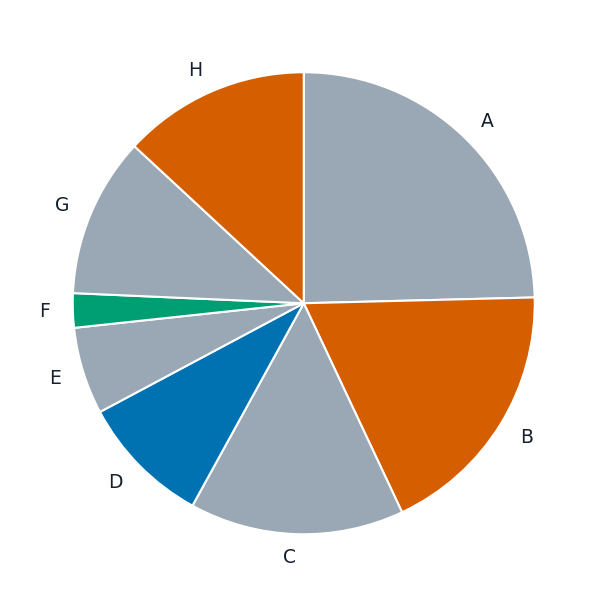

In [5]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(S8.share_pct, labels=S8.slice, startangle=90, counterclock=False,
       colors=[PALETTE["series"][i % 3] if i % 2 else PALETTE["muted"] for i in range(8)],
       wedgeprops={"edgecolor": "white"})
save(fig, "pie_stimulus.png"); plt.show()

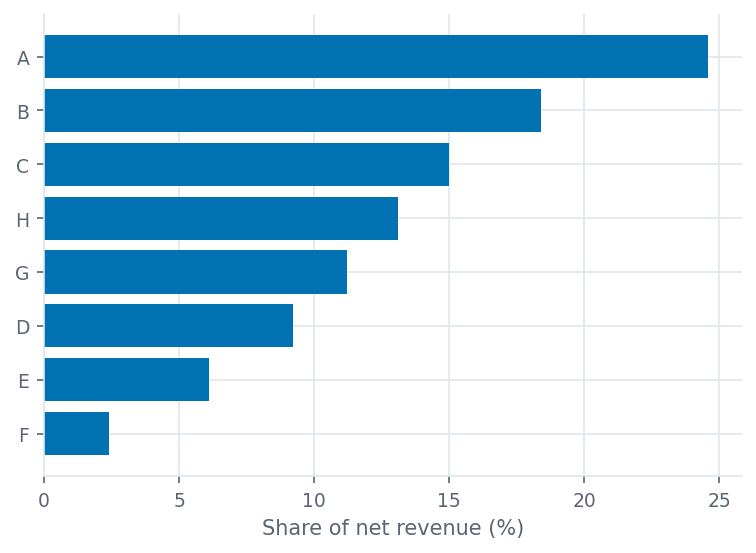

In [6]:
s = S8.sort_values("share_pct")
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(s.slice, s.share_pct, color=PALETTE["series"][0])
ax.set_xlabel("Share of net revenue (%)"); ax.set_xlim(0)
save(fig, "bars_stimulus.png"); plt.show()

## 3. Run it on a real reader
Set `RUN_TRIAL = True`, show the reader each PNG, and type their A-H order. Times come from `time.perf_counter()`. **Real results only.** Invented results score zero.

In [7]:
RUN_TRIAL = False            # change to True when a real reader is sitting next to you
RESULTS = Path("pie_ranking_results.csv")
if RUN_TRIAL:
    reader = input("Reader id: ").strip()
    rows = []
    for stim in ("pie_stimulus.png", "bars_stimulus.png"):
        input(f"Show figures/{stim}. Press Enter, then the timer starts...")
        t0 = time.perf_counter()
        order = input("Reader's order A-H, largest first: ").strip().upper()
        assert sorted(order) == list("ABCDEFGH"), "the order must use each of A-H exactly once"
        rows.append({"reader": reader, "stimulus": stim, "order": order, "seconds": round(time.perf_counter() - t0, 2)})
    pd.DataFrame(rows).to_csv(RESULTS, index=False)
print("results file exists:", RESULTS.exists())

results file exists: False


## 4. Score it (2 marks)

In [8]:
TRUE_ORDER = "".join(S8.sort_values("share_pct", ascending=False).slice)
print("true order:", TRUE_ORDER)
if RESULTS.exists():
    for _, r in pd.read_csv(RESULTS).iterrows():
        wrong = [i + 1 for i, (a, b) in enumerate(zip(r["order"], TRUE_ORDER)) if a != b]
        print(f"{r['stimulus']:18s} {r['seconds']:>6}s  wrong letters: {len(wrong)}  at ranks {wrong}")
else:
    print("no results yet: run the trial first")

true order: ABCHGDEF
no results yet: run the trial first


**My results and reading:** *No reader has been run yet, so there are no results to report and I am not inventing any.* The expected true order is `A B C H G D E F`. When the trial is done, replace this paragraph with: the seconds for each stimulus, the number of wrong letters and their ranks from the scoring cell above, and whether the top two (A, B) and the bottom one (F) went right and the middle (C 15.0, H 13.1, G 11.2) went wrong. If the reader disagrees with the deck, say so and explain it.

**What a sample of one can and cannot support (true whatever the result):**
- It can show that the stimuli work, that the timing code runs, and what one person did on one afternoon. It can show a specific error such as "this reader swapped H and G".
- It cannot support any claim that pies are slower or less accurate than bars *in general*. One reader has no variance, no confidence interval, and no way to tell a systematic effect from a slip or a lucky guess.
- The two stimuli are not independent. The reader sees the pie first, so by the time of the bars they already know roughly which slices are big. This order effect favours the second stimulus. Counterbalancing (half the readers see bars first) is the fix and needs more readers.
- The clock includes typing eight letters, not only reading the chart, so the seconds are inflated by the same amount on both stimuli.

## 5. My rule (1 mark)
**My rule:** I will draw a pie only when there are two or three mutually exclusive parts that add to a meaningful whole, the share of that whole is the actual question, and the values are printed on it; for anything that needs ranking, comparing across time, or more than three parts, I draw sorted bars.